# 1. Project Overview

## Business Context

The job market is constantly changing, with the availability of job offers fluctuating over time. Monitoring these changes can help identify short-term trends in recruitment activity and provide insights into the dynamics of the market.

This project extends an existing job market data pipeline by introducing a time series forecasting component.

## Project Objective

The main objective is to analyze daily job offer observations and develop a forecasting pipeline to predict the number of observed active job offers for the following day.

The project will explore whether historical observations and time-based features can help predict short-term changes in the number of job offers captured by the data collection pipeline.

## Data Source

The dataset is generated from daily snapshots stored in a PostgreSQL database hosted on Neon. The data collection pipeline retrieves job advertisements from the Adzuna API.

The forecasting dataset contains daily counts of distinct job offers observed in the snapshots, along with lag features and rolling averages derived from historical observations.

## Methodology

The project follows these main stages:

1. Exploratory Data Analysis (EDA) to assess data quality, identify patterns, and understand changes over time.
2. Baseline forecasting to establish a reference performance level.
3. Machine Learning experiments using time-based features and regression models.
4. Deep Learning experiments, subject to sufficient historical data.
5. Model evaluation and comparison using appropriate forecasting metrics, including Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

## Scope and Limitations

The initial dataset contains a limited number of daily observations. Therefore, early experiments are intended to validate the forecasting workflow rather than establish reliable predictive performance.

The number of observed job offers should not be interpreted as the total number of vacancies available in the Polish job market. API result limits, pagination, and changes in result ranking may affect the observations collected on each day.

Model complexity will be increased only when sufficient historical data is available to support meaningful training and evaluation.

# 2. Imports

In [15]:
from pathlib import Path
import pandas as pd

import matplotlib.pyplot as plt

# 3. Load Data

The dataset was loaded from a file into a Pandas DataFrame. Basic inspection methods were used to verify that the file exists, check the dataset dimensions, review column data types, and examine summary statistics.

The dataset contains the target variable (`active_offers`), a date column (`snapshot_date`), and time-based features (`lag` and `rolling_mean`).

Initial inspection confirmed that the data was loaded successfully. Missing values in the time-based features are expected due to their lookback requirements.

In [7]:
file_path = (
    Path("..")
    / "data"
    / "ml"
    / "forecasting_dataset_2026-10-29.csv"
)

print("File exists:", file_path.exists())

df = pd.read_csv(file_path)
df.head()

File exists: True


,snapshot_date,active_offers,lag_1,lag_2,lag_3,lag_7,rolling_mean_3,rolling_mean_7
0,2026-10-15,354,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-16,357,354.0,NaN,NaN,NaN,NaN,NaN
2,2026-10-17,349,357.0,354.0,NaN,NaN,NaN,NaN
3,2026-10-18,342,349.0,357.0,354.0,NaN,353.333333,NaN
4,2026-10-19,331,342.0,349.0,357.0,NaN,349.333333,NaN


In [10]:
df.shape

(15, 8)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   snapshot_date   15 non-null     object 
 1   active_offers   15 non-null     int64  
 2   lag_1           14 non-null     float64
 3   lag_2           13 non-null     float64
 4   lag_3           12 non-null     float64
 5   lag_7           8 non-null      float64
 6   rolling_mean_3  12 non-null     float64
 7   rolling_mean_7  8 non-null      float64
dtypes: float64(6), int64(1), object(1)
memory usage: 1.1+ KB


In [9]:
df.describe()

,active_offers,lag_1,lag_2,lag_3,lag_7,rolling_mean_3,rolling_mean_7
count,15.000000,14.000000,13.000000,12.000000,8.000000,12.000000,8.000000
mean,325.866667,328.357143,330.538462,332.416667,338.125000,328.277778,327.428571
std,19.115688,17.126709,15.671712,14.761488,14.227112,13.939141,8.316270
min,291.000000,300.000000,308.000000,311.000000,321.000000,306.333333,316.142857
25%,314.500000,318.750000,321.000000,322.500000,326.750000,322.333333,321.571429
50%,326.000000,327.000000,328.000000,328.500000,336.500000,324.833333,326.857143
75%,336.500000,339.250000,342.000000,343.750000,350.250000,335.416667,332.535714
max,357.000000,357.000000,357.000000,357.000000,357.000000,353.333333,340.571429


# 4. Data Quality & Cleaning

- **Date range:** 2026-10-15 to 2026-10-29
- **Invalid dates:** 0
- **Duplicate dates:** 0
- **Chronological order:** Correct
- **Missing days:** 0
- **Lag features:** All passed validation
- **Rolling means:** `rolling_mean_3` passed; `rolling_mean_7` failed validation

**Conclusion:** The dataset passed the main data quality checks. The `rolling_mean_7` calculation or validation logic requires further investigation

In [11]:
df.isna().sum()

snapshot_date     0
active_offers     0
lag_1             1
lag_2             2
lag_3             3
lag_7             7
rolling_mean_3    3
rolling_mean_7    7
dtype: int64

In [12]:
df["snapshot_date"].min(), df["snapshot_date"].max()

('2026-10-15', '2026-10-29')

In [25]:
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"], errors="coerce")

print("Invalid dates:", df["snapshot_date"].isna().sum())
print("Duplicate dates:", df["snapshot_date"].duplicated().sum())
print("Chronologically sorted:", df["snapshot_date"].is_monotonic_increasing)

dates = df["snapshot_date"].dropna().sort_values()
print("Missing days:", dates.diff().gt(pd.Timedelta(days=1)).sum())

Invalid dates: 0
Duplicate dates: 0
Chronologically sorted: True
Missing days: 0


In [26]:
df = df.sort_values("snapshot_date").reset_index(drop=True)

for lag in [1, 2, 3, 7]:
    expected = df["active_offers"].shift(lag)
    print(f"lag_{lag}:", df[f"lag_{lag}"].equals(expected))

for window in [3, 7]:
    expected = df["active_offers"].shift(1).rolling(window).mean()
    print(f"rolling_mean_{window}:", df[f"rolling_mean_{window}"].equals(expected))

lag_1: True
lag_2: True
lag_3: True
lag_7: True
rolling_mean_3: True
rolling_mean_7: False


# 5. Feature Engineering

Two additional features were created to capture changes in active offers over time:

- `daily_change`: Absolute daily change in active offers.
- `daily_change_pct`: Percentage daily change in active offers.

These features help identify daily increases and decreases in the number of active offers.

In [27]:
df["daily_change"] = df["active_offers"].diff()

df["daily_change_pct"] = (
    df["active_offers"].pct_change() * 100
)

# 6. Exploratory data analysis

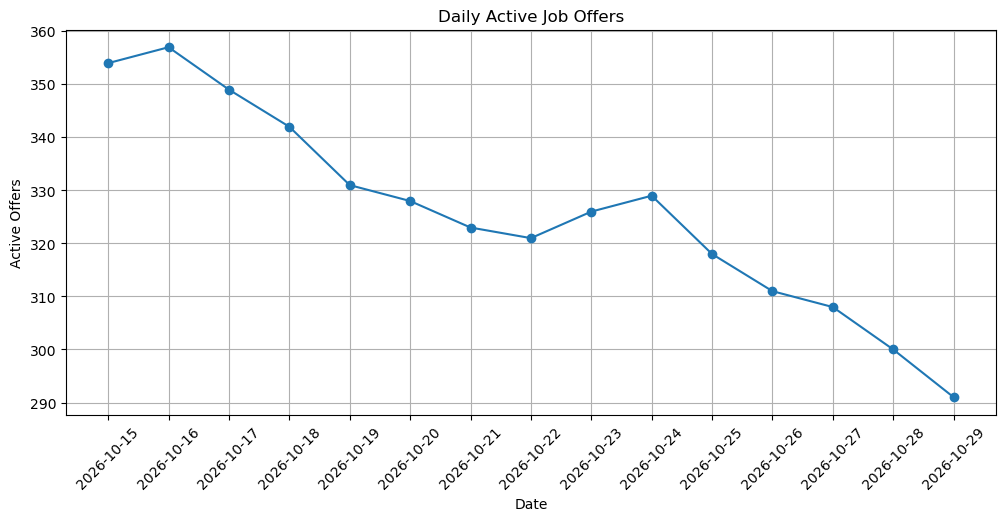

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["snapshot_date"],
    df["active_offers"],
    marker="o"
)

plt.title("Daily Active Job Offers")
plt.xlabel("Date")
plt.ylabel("Active Offers")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

# 6. Target definition